In [ ]:
# -*- coding: utf-8 -*-
"""
Bước 1: tự tính chỉ số Gini và tự chọn câu hỏi tốt nhất.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, export_text

# Mười khách vay để tính tay, giống hệt bảng trên slide
nho = pd.DataFrame({
    "thu_nhap": [6, 8, 9, 11, 13, 15, 18, 20, 25, 30],
    "co_viec_on_dinh": [0, 0, 0, 1, 1, 1, 1, 1, 1, 1],
    "tra_dung_han": [0, 1, 0, 0, 1, 1, 0, 1, 1, 1],
})
y = nho["tra_dung_han"].to_numpy()


def gini(nhan):
    """Chi so Gini cua mot nut co hai lop."""
    if len(nhan) == 0:
        return 0.0
    p1 = nhan.mean()
    return 1 - p1 ** 2 - (1 - p1) ** 2


def gini_sau_chia(di_trai):
    """Gini trung binh co trong so cua hai nhanh."""
    trai, phai = y[di_trai], y[~di_trai]
    n = len(y)
    return len(trai) / n * gini(trai) + len(phai) / n * gini(phai)


g_goc = gini(y)
print(f"Gini cua nut goc: {g_goc:.4f}")
print()

# Thử mọi ngưỡng nằm giữa hai mức thu nhập liền nhau
thu = nho["thu_nhap"].to_numpy()
muc = np.sort(np.unique(thu))
print("Cau hoi 'thu_nhap <= nguong ?'")
print(" nguong Gini sau chia Gini giam")
for a, b in zip(muc[:-1], muc[1:]):
    nguong = (a + b) / 2
    g = gini_sau_chia(thu <= nguong)
    print(f" {nguong:6.1f} {g:13.4f} {g_goc - g:9.4f}")
print()

# Câu hỏi thứ hai: có việc làm ổn định không
viec = nho["co_viec_on_dinh"].to_numpy()
g_viec = gini_sau_chia(viec == 0)
print("Cau hoi 'co viec on dinh ?'")
print(f" Gini sau chia {g_viec:.4f}, Gini giam {g_goc - g_viec:.4f}")
print()

# Để scikit-learn tự chọn câu hỏi đầu tiên rồi so với bảng ở trên
cot = ["thu_nhap", "co_viec_on_dinh"]
cay = DecisionTreeClassifier(max_depth=1, random_state=0)
cay.fit(nho[cot], y)
print("Cay mot tang do scikit-learn chon:")
print(export_text(cay, feature_names=cot, show_weights=True))

Gini cua nut goc: 0.4800

Cau hoi 'thu_nhap <= nguong ?'
 nguong Gini sau chia Gini giam
    7.0        0.4000    0.0800
    8.5        0.4750    0.0050
   10.0        0.4190    0.0610
   12.0        0.3167    0.1633
   14.0        0.4000    0.0800
   16.5        0.4500    0.0300
   19.0        0.3429    0.1371
   22.5        0.4000    0.0800
   27.5        0.4444    0.0356

Cau hoi 'co viec on dinh ?'
 Gini sau chia 0.4190, Gini giam 0.0610

Cay mot tang do scikit-learn chon:
|--- thu_nhap <= 12.00
|   |--- weights: [3.00, 1.00] class: 0
|--- thu_nhap >  12.00
|   |--- weights: [1.00, 5.00] class: 1



In [ ]:
"""Bước 2: học một cây nhỏ năm lá trên dữ liệu khách vay rồi đọc nó."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text

df = pd.read_csv("data/khach_vay.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("Ty le khach tra dung han:", round(df["tra_dung_han"].mean(), 2))
print()

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Giới hạn cây chỉ được có 5 lá để còn đọc được bằng mắt
cay = DecisionTreeClassifier(max_leaf_nodes=5, random_state=0)
cay.fit(X_tr, y_tr)

print(f"Do sau {cay.get_depth()}, so la {cay.get_n_leaves()}")
print(export_text(cay, feature_names=list(X.columns),
                  show_weights=True, decimals=3))

a_hoc = accuracy_score(y_tr, cay.predict(X_tr))
a_kt = accuracy_score(y_te, cay.predict(X_te))
print(f"Accuracy tap hoc : {a_hoc:.4f}")
print(f"Accuracy tap kiem tra : {a_kt:.4f}")
print()

# Hai khách mới, đi theo cây để biết mỗi người rơi vào lá nào
moi = pd.DataFrame({
    "thu_nhap": [20.0, 10.0],
    "ty_le_no": [0.4, 0.3],
    "co_viec_on_dinh": [1, 0],
    "so_nguoi_phu_thuoc": [2, 1],
})

du_doan = cay.predict(moi)
xac_suat = cay.predict_proba(moi)[:, 1]

for i in range(len(moi)):
    ket = "dung han" if du_doan[i] == 1 else "tre han"
    print(f"Khach {i + 1}: {ket}, xac suat dung han {xac_suat[i]:.2f}")

Kich thuoc bang: (600, 5)
   thu_nhap  ty_le_no  co_viec_on_dinh  so_nguoi_phu_thuoc  tra_dung_han
0       9.4      0.18                0                   4             0
1      15.8      0.70                0                   2             1
2       6.1      0.79                0                   0             0
3      19.4      1.13                1                   4             0
4      24.8      0.33                1                   0             1

Ty le khach tra dung han: 0.49

Do sau 3, so la 5
|--- thu_nhap <= 15.050
|   |--- ty_le_no <= 0.615
|   |   |--- co_viec_on_dinh <= 0.500
|   |   |   |--- weights: [33.000, 6.000] class: 0
|   |   |--- co_viec_on_dinh >  0.500
|   |   |   |--- weights: [35.000, 47.000] class: 1
|   |--- ty_le_no >  0.615
|   |   |--- weights: [114.000, 14.000] class: 0
|--- thu_nhap >  15.050
|   |--- ty_le_no <= 1.020
|   |   |--- weights: [27.000, 145.000] class: 1
|   |--- ty_le_no >  1.020
|   |   |--- weights: [20.000, 9.000] class: 0

Accu

In [ ]:
# -*- coding: utf-8 -*-
"""Bước 3: để cây mọc tự do, rồi chọn độ sâu bằng kiểm định chéo."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Không đặt giới hạn nào, cây chia tới khi mọi lá đều thuần
tu_do = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
print("Cay moc tu do")
print(f" do sau {tu_do.get_depth()}, so la {tu_do.get_n_leaves()}")

a_hoc = accuracy_score(y_tr, tu_do.predict(X_tr))
a_kt = accuracy_score(y_te, tu_do.predict(X_te))
print(f" tap hoc {a_hoc:.4f}, tap kiem tra {a_kt:.4f}")
print()

# Chọn độ sâu chỉ dựa trên tập học
print("Do sau tap hoc kiem dinh cheo")
diem = {}

for d in range(1, 16):
    mh = DecisionTreeClassifier(max_depth=d, random_state=0)
    diem[d] = cross_val_score(mh, X_tr, y_tr, cv=5).mean()
    hoc = accuracy_score(y_tr, mh.fit(X_tr, y_tr).predict(X_tr))
    print(f" {d:2d} {hoc:.4f} {diem[d]:.4f}")

d_tot = max(diem, key=diem.get)
print()

# Chọn xong mới mở tập kiểm tra, và chỉ mở một lần
tot = DecisionTreeClassifier(max_depth=d_tot, random_state=0)
tot.fit(X_tr, y_tr)

print(f"Do sau tot nhat = {d_tot}, cay co {tot.get_n_leaves()} la")
acc = accuracy_score(y_te, tot.predict(X_te))
print(f"Accuracy tren tap kiem tra = {acc:.4f}")

Cay moc tu do
 do sau 13, so la 92
 tap hoc 1.0000, tap kiem tra 0.7667

Do sau tap hoc kiem dinh cheo
  1 0.7467 0.7244
  2 0.7711 0.7378
  3 0.8000 0.7511
  4 0.8644 0.8089
  5 0.8978 0.8333
  6 0.9133 0.8156
  7 0.9400 0.8067
  8 0.9600 0.7733
  9 0.9800 0.7800
 10 0.9911 0.7822
 11 0.9933 0.7756
 12 0.9978 0.7778
 13 1.0000 0.7733
 14 1.0000 0.7733
 15 1.0000 0.7733

Do sau tot nhat = 5, cay co 27 la
Accuracy tren tap kiem tra = 0.8533


In [ ]:
# -*- coding: utf-8 -*-
"""Bước 4: kiểm chứng cây không cần chuẩn hoá dữ liệu."""

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)


def cay_sau_5():
    return DecisionTreeClassifier(max_depth=5, random_state=0)


# Cây 1: dữ liệu gốc
goc = cay_sau_5().fit(X_tr, y_tr)
du_goc = goc.predict(X_te)

# Cây 2: dữ liệu đã chuẩn hoá, trung bình tính trên riêng tập học
sc = StandardScaler().fit(X_tr)
chuan = cay_sau_5().fit(sc.transform(X_tr), y_tr)
du_chuan = chuan.predict(sc.transform(X_te))

# Cây 3: đổi thu nhập từ triệu đồng sang nghìn đồng
X_tr_n, X_te_n = X_tr.copy(), X_te.copy()
X_tr_n["thu_nhap"] = X_tr_n["thu_nhap"] * 1000
X_te_n["thu_nhap"] = X_te_n["thu_nhap"] * 1000
nghin = cay_sau_5().fit(X_tr_n, y_tr)
du_nghin = nghin.predict(X_te_n)

print("Accuracy tren tap kiem tra")
print(f" du lieu goc : {accuracy_score(y_te, du_goc):.4f}")
print(f" da chuan hoa : {accuracy_score(y_te, du_chuan):.4f}")
print(f" thu nhap nghin dong: {accuracy_score(y_te, du_nghin):.4f}")
print()
print("So khach bi doan khac cay goc")
print(f" da chuan hoa : {(du_chuan != du_goc).sum()}")
print(f" thu nhap nghin dong: {(du_nghin != du_goc).sum()}")
print()
print("Nguong cua cau hoi goc")
print(f" du lieu goc : {goc.tree_.threshold[0]:.2f}")
print(f" thu nhap nghin dong: {nghin.tree_.threshold[0]:.2f}")

Accuracy tren tap kiem tra
 du lieu goc : 0.8533
 da chuan hoa : 0.8533
 thu nhap nghin dong: 0.8533

So khach bi doan khac cay goc
 da chuan hoa : 0
 thu nhap nghin dong: 0

Nguong cua cau hoi goc
 du lieu goc : 15.05
 thu nhap nghin dong: 15050.00


In [ ]:
# -*- coding: utf-8 -*-
"""Bước 5: trồng rừng ngẫu nhiên và so với một cây."""

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Bốc mẫu có hoàn lại: rút 450 lần từ 450 khách
rng = np.random.default_rng(0)
n = len(X_tr)
chi_so = rng.integers(0, n, n)
khac = len(np.unique(chi_so))
print(f"Boc {n} lan, co {khac} khach khac nhau ({khac / n:.0%})")
print()

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)
print("Rung 200 cay")
print(f" tap hoc : {accuracy_score(y_tr, rung.predict(X_tr)):.4f}")
print(f" tap kiem tra : {accuracy_score(y_te, rung.predict(X_te)):.4f}")
print()

print("So cay accuracy tap kiem tra")
for m in [1, 10, 50, 200, 400]:
    r = RandomForestClassifier(n_estimators=m, random_state=0)
    r.fit(X_tr, y_tr)
    print(f" {m:4d} {accuracy_score(y_te, r.predict(X_te)):.4f}")
print()

# Bảng tổng kết ba mô hình trên cùng tập kiểm tra
ba_mo_hinh = {
    "Cay moc tu do": DecisionTreeClassifier(random_state=0),
    "Cay sau 5": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Rung 200 cay": rung,
}

print("Mo hinh tap hoc tap kiem tra")
for ten, mh in ba_mo_hinh.items():
    mh.fit(X_tr, y_tr)
    a = accuracy_score(y_tr, mh.predict(X_tr))
    b = accuracy_score(y_te, mh.predict(X_te))
    print(f" {ten:14s} {a:.4f} {b:.4f}")

Boc 450 lan, co 286 khach khac nhau (64%)

Rung 200 cay
 tap hoc : 1.0000
 tap kiem tra : 0.9000

So cay accuracy tap kiem tra
    1 0.7933
   10 0.8467
   50 0.8733
  200 0.9000
  400 0.9000

Mo hinh tap hoc tap kiem tra
 Cay moc tu do  1.0000 0.7667
 Cay sau 5      0.8978 0.8533
 Rung 200 cay   1.0000 0.9000


In [ ]:
# -*- coding: utf-8 -*-
"""Bước 6: đọc độ quan trọng của đặc trưng, và thấy giới hạn của nó."""

import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/khach_vay.csv")
X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

rung = RandomForestClassifier(n_estimators=200, random_state=0)
rung.fit(X_tr, y_tr)

qt = pd.Series(rung.feature_importances_, index=X.columns)
print("Do quan trong, bon cot that")
print(qt.sort_values(ascending=False).round(3).to_string())
print("Tong:", round(qt.sum(), 3))
print()

# Thêm một cột toàn số ngẫu nhiên, chẳng liên quan gì tới việc trả nợ
rng = np.random.default_rng(0)
X_tr_nn = X_tr.copy()
X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr))

rung_nn = RandomForestClassifier(n_estimators=200, random_state=0)
rung_nn.fit(X_tr_nn, y_tr)

qt_nn = pd.Series(rung_nn.feature_importances_, index=X_tr_nn.columns)
print("Do quan trong, them mot cot ngau nhien")
print(qt_nn.sort_values(ascending=False).round(3).to_string())

Do quan trong, bon cot that
thu_nhap              0.479
ty_le_no              0.339
so_nguoi_phu_thuoc    0.093
co_viec_on_dinh       0.088
Tong: 1.0

Do quan trong, them mot cot ngau nhien
thu_nhap              0.427
ty_le_no              0.270
so_ngau_nhien         0.150
co_viec_on_dinh       0.077
so_nguoi_phu_thuoc    0.076


In [ ]:
# -*- coding: utf-8 -*-
"""Bước 7: cây quyết định cho bài toán hồi quy, trên dữ liệu giá nhà."""

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text

df = pd.read_csv("data/gia_nha.csv")
X = df[["dien_tich"]]
y = df["gia"]

# Cùng cách chia với bài 1 để so sánh công bằng
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

cay = DecisionTreeRegressor(max_depth=3, random_state=0)
cay.fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)

print(f"Cay hoi quy sau 3 co {cay.get_n_leaves()} la")
print(export_text(cay, feature_names=["dien_tich"], decimals=1))

print("MAE tren tap kiem tra (ty dong)")
mae_cay = mean_absolute_error(y_te, cay.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f" Cay sau 3 : {mae_cay:.4f}")
print(f" Duong thang : {mae_duong:.4f}")
print()

can_moi = pd.DataFrame({"dien_tich": [60.0, 100.0, 150.0, 250.0]})
print("Du doan cho bon can moi (ty dong)")
print(" dien tich cay duong thang")
for dt, a, b in zip(
    can_moi["dien_tich"], cay.predict(can_moi), duong.predict(can_moi)
):
    print(f" {dt:6.0f} m2 {a:6.2f} {b:6.2f}")

Cay hoi quy sau 3 co 8 la
|--- dien_tich <= 73.9
|   |--- dien_tich <= 64.7
|   |   |--- dien_tich <= 50.5
|   |   |   |--- value: [4.2]
|   |   |--- dien_tich >  50.5
|   |   |   |--- value: [4.9]
|   |--- dien_tich >  64.7
|   |   |--- dien_tich <= 68.5
|   |   |   |--- value: [5.3]
|   |   |--- dien_tich >  68.5
|   |   |   |--- value: [5.9]
|--- dien_tich >  73.9
|   |--- dien_tich <= 93.8
|   |   |--- dien_tich <= 82.5
|   |   |   |--- value: [6.8]
|   |   |--- dien_tich >  82.5
|   |   |   |--- value: [7.4]
|   |--- dien_tich >  93.8
|   |   |--- dien_tich <= 107.7
|   |   |   |--- value: [8.3]
|   |   |--- dien_tich >  107.7
|   |   |   |--- value: [9.4]

MAE tren tap kiem tra (ty dong)
 Cay sau 3 : 0.5039
 Duong thang : 0.2578

Du doan cho bon can moi (ty dong)
 dien tich cay duong thang
     60 m2   4.92   5.12
    100 m2   8.32   8.24
    150 m2   9.40  12.13
    250 m2   9.40  19.91


Bài tập 1

So khach tap hoc: 450
So khach tap kiem tra: 150


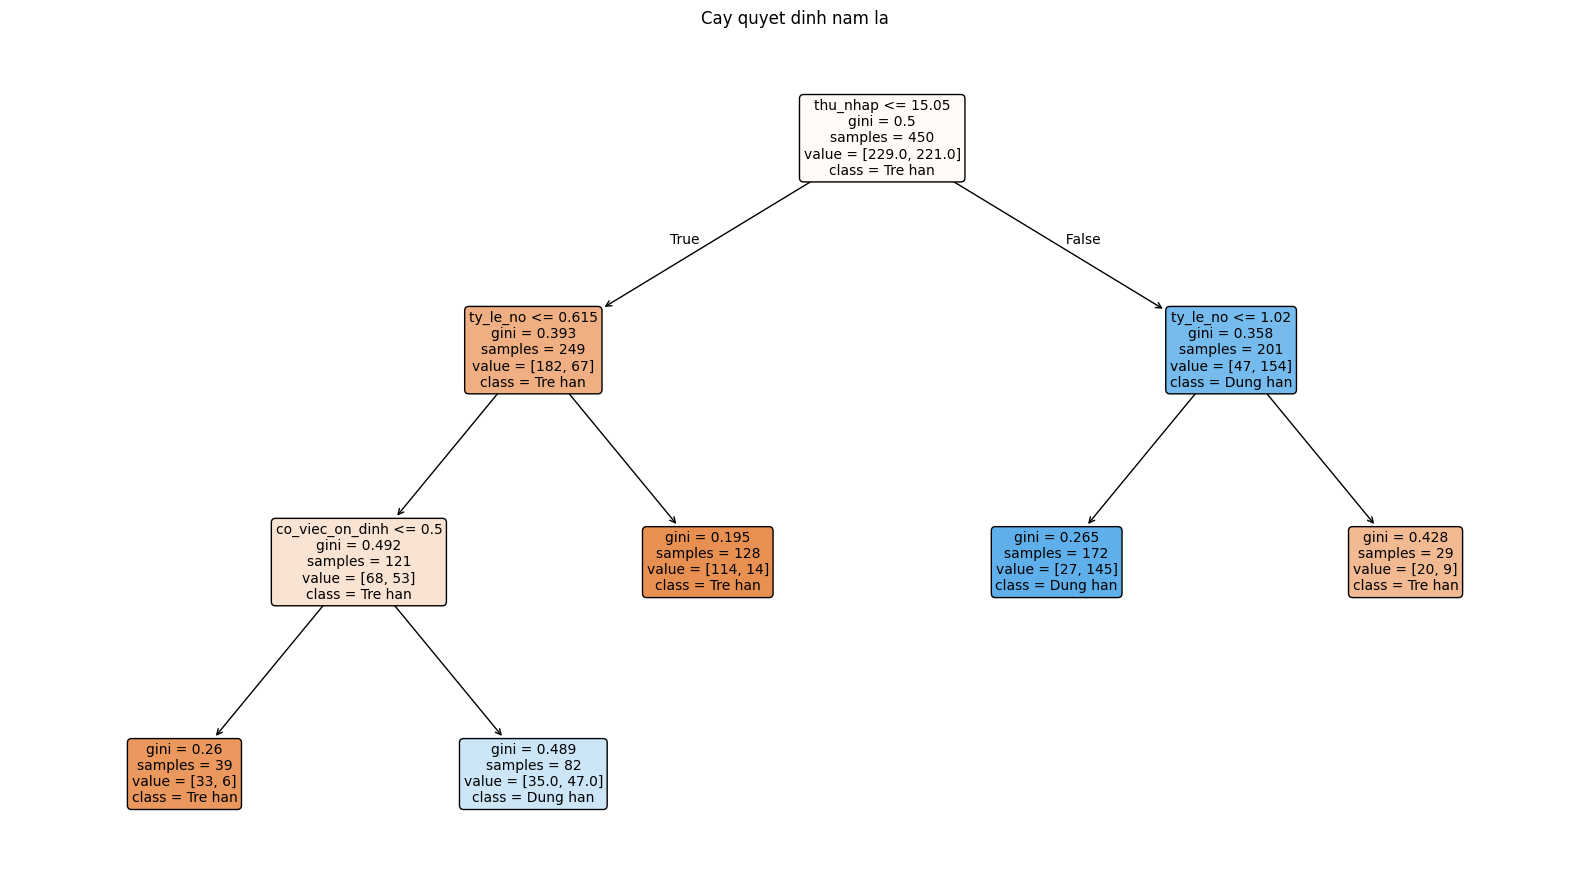

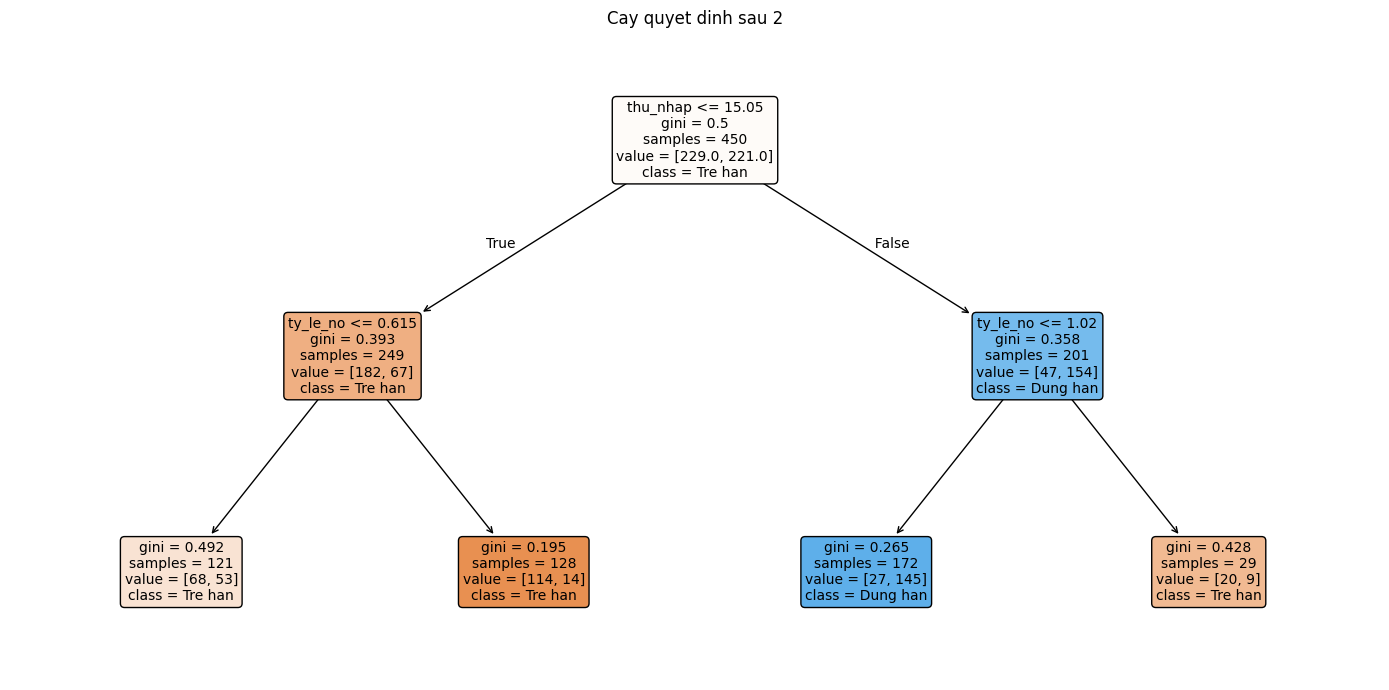

La trai 1: class=0, ty le tre han=0.5620, ty le dung han=0.4380
La trai 2: class=0, ty le tre han=0.8906, ty le dung han=0.1094
Hai la cung ket luan: True


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree
)
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.inspection import permutation_importance

df = pd.read_csv("data/khach_vay.csv")

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

print("So khach tap hoc:", len(X_tr))
print("So khach tap kiem tra:", len(X_te))
# Huấn luyện và vẽ cây năm lá
cay_nam_la = DecisionTreeClassifier(
    max_leaf_nodes=5,
    random_state=0
)
cay_nam_la.fit(X_tr, y_tr)

plt.figure(figsize=(16, 9))
plot_tree(
    cay_nam_la,
    feature_names=list(X.columns),
    class_names=["Tre han", "Dung han"],
    filled=True,
    rounded=True,
    precision=3,
    fontsize=10
)
plt.title("Cay quyet dinh nam la")
plt.tight_layout()
plt.savefig("cay_nam_la.png", dpi=300, bbox_inches="tight")
plt.show()

# Huấn luyện một cây mới có độ sâu tối đa bằng 2
cay_sau_2 = DecisionTreeClassifier(
    max_depth=2,
    random_state=0
)
cay_sau_2.fit(X_tr, y_tr)

plt.figure(figsize=(14, 7))
plot_tree(
    cay_sau_2,
    feature_names=list(X.columns),
    class_names=["Tre han", "Dung han"],
    filled=True,
    rounded=True,
    precision=3,
    fontsize=10
)
plt.title("Cay quyet dinh sau 2")
plt.tight_layout()
plt.savefig("cay_sau_2.png", dpi=300, bbox_inches="tight")
plt.show()

# Đọc kết luận và tỷ lệ lớp của hai lá thuộc nhánh trái
nut_trai = cay_sau_2.tree_.children_left[0]
hai_la = [
    cay_sau_2.tree_.children_left[nut_trai],
    cay_sau_2.tree_.children_right[nut_trai]
]

ket_luan = []

for i, nut in enumerate(hai_la, start=1):
    so_luong = cay_sau_2.tree_.value[nut][0]
    ty_le = so_luong / so_luong.sum()
    nhan = cay_sau_2.classes_[np.argmax(ty_le)]
    ket_luan.append(nhan)

    print(
        f"La trai {i}: class={nhan}, "
        f"ty le tre han={ty_le[0]:.4f}, "
        f"ty le dung han={ty_le[1]:.4f}"
    )

print("Hai la cung ket luan:", ket_luan[0] == ket_luan[1])

Nhận xét: Cây quyết định giới hạn 5 lá và độ sâu 2 giúp mô hình đơn giản, dễ quan sát. Hai lá bên trái có thể cùng kết luận nhưng vẫn được chia vì tỷ lệ các lớp khác nhau, giúp giảm độ hỗn tạp Gini.

Bài tập 2

In [14]:
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

# Đọc dữ liệu khách vay
df = pd.read_csv("data/khach_vay.csv")

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

# Chia dữ liệu thành tập học và tập kiểm tra
X_tr, X_te, y_tr, y_te = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

def gini(nhan):
    """Tính Gini từ tỷ lệ các lớp trong một nút."""
    nhan = np.asarray(nhan)

    if len(nhan) == 0:
        return 0.0

    _, so_luong = np.unique(nhan, return_counts=True)
    ty_le = so_luong / len(nhan)

    return 1.0 - np.sum(ty_le ** 2)


def tim_cau_hoi(X, y):
    """Trả về cột và ngưỡng làm Gini giảm nhiều nhất."""
    y = np.asarray(y)
    n = len(y)

    gini_goc = gini(y)
    giam_tot_nhat = -np.inf
    cot_tot_nhat = None
    nguong_tot_nhat = None

    for cot in X.columns:
        gia_tri = X[cot].to_numpy()
        cac_muc = np.sort(np.unique(gia_tri))

        # Chỉ cần thử trung điểm giữa hai giá trị liền nhau
        for a, b in zip(cac_muc[:-1], cac_muc[1:]):
            nguong = (float(a) + float(b)) / 2
            di_trai = gia_tri <= nguong

            y_trai = y[di_trai]
            y_phai = y[~di_trai]

            gini_chia = (
                len(y_trai) / n * gini(y_trai)
                + len(y_phai) / n * gini(y_phai)
            )
            giam = gini_goc - gini_chia

            if giam > giam_tot_nhat:
                giam_tot_nhat = giam
                cot_tot_nhat = cot
                nguong_tot_nhat = nguong

    if cot_tot_nhat is None:
        raise ValueError("Khong co nguong chia hop le.")

    return cot_tot_nhat, nguong_tot_nhat


# Tìm câu hỏi trên tập học
cot_tot, nguong_tot = tim_cau_hoi(X_tr, y_tr)

di_trai = X_tr[cot_tot].to_numpy() <= nguong_tot
nhan = y_tr.to_numpy()

gini_chia = (
    di_trai.mean() * gini(nhan[di_trai])
    + (~di_trai).mean() * gini(nhan[~di_trai])
)

print(f"Cau hoi tu tinh: {cot_tot} <= {nguong_tot:.4f}")
print(f"Gini nut goc: {gini(nhan):.4f}")
print(f"Gini sau chia: {gini_chia:.4f}")
print(f"Gini giam: {gini(nhan) - gini_chia:.4f}")

# Đối chiếu với câu hỏi gốc do scikit-learn chọn
cay_goc = DecisionTreeClassifier(max_depth=1, random_state=0)
cay_goc.fit(X_tr, y_tr)

cot_sklearn = X.columns[cay_goc.tree_.feature[0]]
nguong_sklearn = cay_goc.tree_.threshold[0]

print(
    f"Cau hoi sklearn: "
    f"{cot_sklearn} <= {nguong_sklearn:.4f}"
)
print(
    "Hai ket qua trung nhau:",
    cot_tot == cot_sklearn
    and np.isclose(nguong_tot, nguong_sklearn)
)

Cau hoi tu tinh: thu_nhap <= 15.0500
Gini nut goc: 0.4998
Gini sau chia: 0.3777
Gini giam: 0.1221
Cau hoi sklearn: thu_nhap <= 15.0500
Hai ket qua trung nhau: True


Nhận xét: Hàm tự viết đã tìm được câu hỏi phân chia dữ liệu có mức giảm Gini lớn nhất. Kết quả được đối chiếu với Scikit-learn để kiểm tra độ chính xác. Nếu hai kết quả trùng nhau, chứng tỏ cách tính và lựa chọn ngưỡng chia là phù hợp.

Bài tập 3

In [15]:
# -*- coding: utf-8 -*-

import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score


# Đọc và chia dữ liệu
df = pd.read_csv("data/khach_vay.csv")

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

bang_do_sau = []
bang_so_sanh = []

for tieu_chi in ["gini", "entropy"]:
    diem_theo_do_sau = {}

    # Chọn độ sâu chỉ trên tập học
    for d in range(1, 16):
        mh = DecisionTreeClassifier(
            criterion=tieu_chi,
            max_depth=d,
            random_state=0
        )

        diem_cv = cross_val_score(
            mh,
            X_tr,
            y_tr,
            cv=5,
            scoring="accuracy"
        ).mean()

        mh.fit(X_tr, y_tr)
        diem_hoc = accuracy_score(y_tr, mh.predict(X_tr))

        diem_theo_do_sau[d] = diem_cv

        bang_do_sau.append({
            "criterion": tieu_chi,
            "max_depth": d,
            "accuracy_train": diem_hoc,
            "accuracy_cv": diem_cv
        })

    # Nếu bằng điểm, chọn độ sâu nhỏ hơn
    d_tot = max(
        diem_theo_do_sau,
        key=diem_theo_do_sau.get
    )

    mh_tot = DecisionTreeClassifier(
        criterion=tieu_chi,
        max_depth=d_tot,
        random_state=0
    )
    mh_tot.fit(X_tr, y_tr)

    # Đánh giá mô hình đã chọn trên tập kiểm tra
    acc_test = accuracy_score(
        y_te,
        mh_tot.predict(X_te)
    )

    bang_so_sanh.append({
        "criterion": tieu_chi,
        "best_depth": d_tot,
        "accuracy_cv": diem_theo_do_sau[d_tot],
        "accuracy_test": acc_test
    })

print("KET QUA THEO DO SAU")
print(
    pd.DataFrame(bang_do_sau)
    .round(4)
    .to_string(index=False)
)

ket_qua = pd.DataFrame(bang_so_sanh)

print("\nSO SANH GINI VA ENTROPY")
print(ket_qua.round(4).to_string(index=False))

acc_gini = ket_qua.loc[
    ket_qua["criterion"] == "gini",
    "accuracy_test"
].iloc[0]

acc_entropy = ket_qua.loc[
    ket_qua["criterion"] == "entropy",
    "accuracy_test"
].iloc[0]

chenh_lech = abs(acc_entropy - acc_gini) * 100

print(
    f"\nNhan xet: Doi Gini sang entropy lam accuracy "
    f"kiem tra chenh {chenh_lech:.2f} diem phan tram."
)

KET QUA THEO DO SAU
criterion  max_depth  accuracy_train  accuracy_cv
     gini          1          0.7467       0.7244
     gini          2          0.7711       0.7378
     gini          3          0.8000       0.7511
     gini          4          0.8644       0.8089
     gini          5          0.8978       0.8333
     gini          6          0.9133       0.8156
     gini          7          0.9400       0.8067
     gini          8          0.9600       0.7733
     gini          9          0.9800       0.7800
     gini         10          0.9911       0.7822
     gini         11          0.9933       0.7756
     gini         12          0.9978       0.7778
     gini         13          1.0000       0.7733
     gini         14          1.0000       0.7733
     gini         15          1.0000       0.7733
  entropy          1          0.7467       0.7244
  entropy          2          0.7711       0.7133
  entropy          3          0.7733       0.7489
  entropy          4          

Nhận xét: Gini và Entropy đều được sử dụng để xây dựng cây quyết định. Việc lựa chọn độ sâu bằng Cross-validation giúp tìm mô hình phù hợp. Qua kết quả Accuracy trên tập kiểm tra, có thể đánh giá tiêu chí nào hoạt động tốt hơn trên bộ dữ liệu này.

Bài tập 4

In [16]:
# -*- coding: utf-8 -*-

import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score


# Đọc và chia dữ liệu
df = pd.read_csv("data/khach_vay.csv")

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

cac_gia_tri = [1, 2, 5, 10, 20, 40]
bang_leaf = []

# Không giới hạn độ sâu, chỉ thay min_samples_leaf
for m in cac_gia_tri:
    mh = DecisionTreeClassifier(
        min_samples_leaf=m,
        random_state=0
    )

    diem_cv = cross_val_score(
        mh,
        X_tr,
        y_tr,
        cv=5,
        scoring="accuracy"
    ).mean()

    mh.fit(X_tr, y_tr)

    bang_leaf.append({
        "min_samples_leaf": m,
        "depth": mh.get_depth(),
        "n_leaves": mh.get_n_leaves(),
        "accuracy_train": accuracy_score(
            y_tr, mh.predict(X_tr)
        ),
        "accuracy_cv": diem_cv
    })

bang_leaf = pd.DataFrame(bang_leaf)

print("KET QUA KIEM DINH CHEO")
print(bang_leaf.round(4).to_string(index=False))

# Chọn tham số theo điểm kiểm định chéo cao nhất
hang_tot = bang_leaf.loc[
    bang_leaf["accuracy_cv"].idxmax()
]
m_tot = int(hang_tot["min_samples_leaf"])

cac_mo_hinh = {
    f"min_samples_leaf={m_tot}": DecisionTreeClassifier(
        min_samples_leaf=m_tot,
        random_state=0
    ),
    "max_depth=5": DecisionTreeClassifier(
        max_depth=5,
        random_state=0
    )
}

bang_cuoi = []

# Chấm mỗi mô hình cuối cùng một lần trên tập kiểm tra
for ten, mh in cac_mo_hinh.items():
    mh.fit(X_tr, y_tr)

    bang_cuoi.append({
        "model": ten,
        "depth": mh.get_depth(),
        "n_leaves": mh.get_n_leaves(),
        "accuracy_test": accuracy_score(
            y_te, mh.predict(X_te)
        )
    })

ket_qua = pd.DataFrame(bang_cuoi)

print("\nMin_samples_leaf tot nhat:", m_tot)
print("\nSO SANH HAI CACH CAT TIA")
print(ket_qua.round(4).to_string(index=False))

acc_leaf = ket_qua.iloc[0]["accuracy_test"]
acc_depth = ket_qua.iloc[1]["accuracy_test"]

if acc_leaf > acc_depth:
    print(
        "\nNhan xet: Gioi han so khach toi thieu o la "
        "cho accuracy kiem tra cao hon."
    )
elif acc_leaf < acc_depth:
    print(
        "\nNhan xet: Gioi han do sau bang 5 "
        "cho accuracy kiem tra cao hon."
    )
else:
    print(
        "\nNhan xet: Hai cach cho accuracy "
        "kiem tra bang nhau."
    )

KET QUA KIEM DINH CHEO
 min_samples_leaf  depth  n_leaves  accuracy_train  accuracy_cv
                1     13        92          1.0000       0.7733
                2     11        72          0.9467       0.7822
                5     10        46          0.8956       0.8067
               10      8        30          0.8600       0.8089
               20      7        17          0.8422       0.8089
               40      4         8          0.7822       0.7133

Min_samples_leaf tot nhat: 10

SO SANH HAI CACH CAT TIA
              model  depth  n_leaves  accuracy_test
min_samples_leaf=10      8        30         0.8467
        max_depth=5      5        27         0.8533

Nhan xet: Gioi han do sau bang 5 cho accuracy kiem tra cao hon.


Nhận xét: min_samples_leaf và max_depth đều giúp hạn chế cây phát triển quá phức tạp. Kết quả cho thấy phương pháp có Accuracy kiểm tra cao hơn sẽ phù hợp hơn với bộ dữ liệu này.

Bài tập 5

In [17]:
# -*- coding: utf-8 -*-

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance


# Đọc và chia dữ liệu
df = pd.read_csv("data/khach_vay.csv")

X = df.drop(columns="tra_dung_han")
y = df["tra_dung_han"]

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

# Thêm cột ngẫu nhiên cho cả hai tập
rng = np.random.default_rng(0)

X_tr_nn = X_tr.copy()
X_te_nn = X_te.copy()

X_tr_nn["so_ngau_nhien"] = rng.random(len(X_tr_nn))
X_te_nn["so_ngau_nhien"] = rng.random(len(X_te_nn))

# Huấn luyện rừng
rung_nn = RandomForestClassifier(
    n_estimators=200,
    random_state=0
)
rung_nn.fit(X_tr_nn, y_tr)

# Độ quan trọng dựa trên mức giảm Gini
mdi = pd.Series(
    rung_nn.feature_importances_,
    index=X_tr_nn.columns
)

# Độ quan trọng bằng xáo trộn trên tập kiểm tra
hoan_vi = permutation_importance(
    rung_nn,
    X_te_nn,
    y_te,
    scoring="accuracy",
    n_repeats=20,
    random_state=0
)

bang_qt = pd.DataFrame({
    "MDI": mdi,
    "permutation_mean": hoan_vi.importances_mean,
    "permutation_std": hoan_vi.importances_std
})

# Các cột bằng điểm được tính đồng hạng
bang_qt["rank_MDI"] = (
    bang_qt["MDI"]
    .rank(ascending=False, method="min")
    .astype(int)
)

bang_qt["rank_permutation"] = (
    bang_qt["permutation_mean"]
    .rank(ascending=False, method="min")
    .astype(int)
)

acc = accuracy_score(
    y_te,
    rung_nn.predict(X_te_nn)
)

print(f"Accuracy tap kiem tra: {acc:.4f}")

print("\nDO QUAN TRONG CUA NAM COT")
print(
    bang_qt
    .sort_values("permutation_mean", ascending=False)
    .round(4)
    .to_string()
)

cot_nn = bang_qt.loc["so_ngau_nhien"]

print(
    f"\nCot ngau nhien xep hang "
    f"{int(cot_nn['rank_MDI'])} theo MDI."
)
print(
    f"Cot ngau nhien xep hang "
    f"{int(cot_nn['rank_permutation'])} theo permutation."
)
print(
    f"Permutation mean cua cot ngau nhien: "
    f"{cot_nn['permutation_mean']:.4f}"
)

print(
    "\nGiai thich: MDI co the danh gia cao cot ngau nhien "
    "vi cot nay co nhieu nguong chia."
)
print(
    "Permutation do muc giam accuracy tren tap kiem tra, "
    "nen cot vo dung thuong co diem gan 0 hoac am."
)

Accuracy tap kiem tra: 0.9067

DO QUAN TRONG CUA NAM COT
                       MDI  permutation_mean  permutation_std  rank_MDI  rank_permutation
thu_nhap            0.4269            0.3073           0.0242         1                 1
ty_le_no            0.2696            0.1993           0.0357         2                 2
co_viec_on_dinh     0.0773            0.1117           0.0155         4                 3
so_nguoi_phu_thuoc  0.0764            0.0497           0.0199         5                 4
so_ngau_nhien       0.1499            0.0017           0.0111         3                 5

Cot ngau nhien xep hang 3 theo MDI.
Cot ngau nhien xep hang 5 theo permutation.
Permutation mean cua cot ngau nhien: 0.0017

Giai thich: MDI co the danh gia cao cot ngau nhien vi cot nay co nhieu nguong chia.
Permutation do muc giam accuracy tren tap kiem tra, nen cot vo dung thuong co diem gan 0 hoac am.


Nhận xét: MDI và Permutation đều đánh giá độ quan trọng của đặc trưng. Tuy nhiên, MDI có thể đánh giá cao cột ngẫu nhiên, trong khi Permutation phản ánh mức ảnh hưởng của đặc trưng đến Accuracy. Cột ngẫu nhiên thường có điểm Permutation gần 0 hoặc âm, cho thấy ít giá trị dự đoán.

Bài tập 6

In [18]:
# -*- coding: utf-8 -*-

import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error


# Đọc dữ liệu giá nhà
df = pd.read_csv("data/gia_nha.csv")

X = df[["dien_tich"]]
y = df["gia"]

# Chia dữ liệu giống mục 8 của tài liệu
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

cac_mo_hinh = {
    "Cay sau 3": DecisionTreeRegressor(
        max_depth=3,
        random_state=0
    ),
    "Duong thang": LinearRegression(),
    "Rung 200 cay": RandomForestRegressor(
        n_estimators=200,
        random_state=0
    )
}

can_moi = pd.DataFrame({
    "dien_tich": [150.0, 250.0]
})

bang_ket_qua = []

# Huấn luyện và so sánh ba mô hình
for ten, mh in cac_mo_hinh.items():
    mh.fit(X_tr, y_tr)

    du_doan_test = mh.predict(X_te)
    gia_moi = mh.predict(can_moi)

    bang_ket_qua.append({
        "model": ten,
        "MAE_test": mean_absolute_error(
            y_te, du_doan_test
        ),
        "gia_150m2": gia_moi[0],
        "gia_250m2": gia_moi[1]
    })

ket_qua = pd.DataFrame(bang_ket_qua)

print("SO SANH MO HINH, DON VI TY DONG")
print(ket_qua.round(4).to_string(index=False))

print(
    "\nDien tich lon nhat trong tap hoc:",
    X_tr["dien_tich"].max()
)

# Kiểm tra cách rừng tổng hợp dự đoán của từng cây
rung = cac_mo_hinh["Rung 200 cay"]
can_250 = pd.DataFrame({"dien_tich": [250.0]})

gia_tung_cay = np.array([
    cay.predict(can_250.to_numpy())[0]
    for cay in rung.estimators_
])

gia_rung = rung.predict(can_250)[0]

print(f"\nGia 250m2 do rung du doan: {gia_rung:.4f}")
print(
    f"Trung binh du doan cua 200 cay: "
    f"{gia_tung_cay.mean():.4f}"
)
print(
    "Hai ket qua trung nhau:",
    np.isclose(gia_rung, gia_tung_cay.mean())
)

tot_nhat = ket_qua.loc[
    ket_qua["MAE_test"].idxmin(),
    "model"
]

print("\nMo hinh co MAE thap nhat:", tot_nhat)

print(
    "\nKet luan: Rung khong ngoai suy duoc xu huong "
    "tang gia ngoai mien dien tich da hoc."
)
print(
    "Moi cay du doan bang gia trung binh tai la; "
    "rung lay trung binh du doan cua 200 cay."
)

SO SANH MO HINH, DON VI TY DONG
       model  MAE_test  gia_150m2  gia_250m2
   Cay sau 3    0.5039     9.4025     9.4025
 Duong thang    0.2578    12.1303    19.9139
Rung 200 cay    0.4559     9.1973     9.1973

Dien tich lon nhat trong tap hoc: 117.5

Gia 250m2 do rung du doan: 9.1973
Trung binh du doan cua 200 cay: 9.1972
Hai ket qua trung nhau: True

Mo hinh co MAE thap nhat: Duong thang

Ket luan: Rung khong ngoai suy duoc xu huong tang gia ngoai mien dien tich da hoc.
Moi cay du doan bang gia trung binh tai la; rung lay trung binh du doan cua 200 cay.


Nhận xét: Rừng ngẫu nhiên kết hợp dự đoán từ 200 cây để đưa ra kết quả. Mô hình có MAE thấp nhất cho kết quả dự đoán tốt nhất trên tập kiểm tra. Tuy nhiên, rừng ngẫu nhiên không thể ngoại suy xu hướng giá nhà vượt ngoài phạm vi diện tích đã học.